In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

print("Ambiente do TP3 configurado com sucesso!")

Ambiente do TP3 configurado com sucesso!


In [2]:
from pathlib import Path

# Localiza a pasta de dados a partir da raiz do projeto
data_dir = Path("data")

print("Pasta de dados encontrada:", data_dir.exists())

if data_dir.exists():
    for arquivo in sorted(data_dir.glob("*.csv")):
        print(f"{arquivo} — {arquivo.stat().st_size:,} bytes")

Pasta de dados encontrada: True
data\customer_support_tickets.csv — 3,982,913 bytes
data\customer_support_tickets_anomalies.csv — 1,706 bytes
data\customer_support_tickets_cleaned.csv — 3,978,477 bytes


In [3]:
from pathlib import Path
import pandas as pd

# Carrega a versão tratada do dataset
arquivo = Path("data") / "customer_support_tickets_cleaned.csv"
df = pd.read_csv(arquivo)

# Visão geral
print("Dimensões do dataset:", df.shape)

print("\nNomes das colunas:")
print(df.columns.tolist())

print("\nTipos de dados:")
print(df.dtypes)

print("\nPrimeiras 5 linhas:")
display(df.head())

print("\nValores ausentes por coluna:")
display(df.isnull().sum().sort_values(ascending=False))

Dimensões do dataset: (8467, 17)

Nomes das colunas:
['Ticket ID', 'Customer Name', 'Customer Email', 'Customer Age', 'Customer Gender', 'Product Purchased', 'Date of Purchase', 'Ticket Type', 'Ticket Subject', 'Ticket Description', 'Ticket Status', 'Resolution', 'Ticket Priority', 'Ticket Channel', 'First Response Time', 'Time to Resolution', 'Customer Satisfaction Rating']

Tipos de dados:
Ticket ID                       float64
Customer Name                       str
Customer Email                      str
Customer Age                    float64
Customer Gender                     str
Product Purchased                   str
Date of Purchase                    str
Ticket Type                         str
Ticket Subject                      str
Ticket Description                  str
Ticket Status                       str
Resolution                          str
Ticket Priority                     str
Ticket Channel                      str
First Response Time                 str
Time 

,Ticket ID,Customer Name,Customer Email,Customer Age,Customer Gender,Product Purchased,Date of Purchase,Ticket Type,Ticket Subject,Ticket Description,Ticket Status,Resolution,Ticket Priority,Ticket Channel,First Response Time,Time to Resolution,Customer Satisfaction Rating
0,1.0,Marisa Obrien,carrollallison@example.com,32.0,Other,GoPro Hero,3/22/2021,Technical issue,Product setup,I'm having an issue with the {product_purchase...,Pending Customer Response,NaN,Critical,Social media,6/1/2023 12:15:36,NaN,NaN
1,2.0,Jessica Rios,clarkeashley@example.com,42.0,Female,LG Smart TV,5/22/2021,Technical issue,Peripheral compatibility,I'm having an issue with the {product_purchase...,Pending Customer Response,NaN,Critical,Chat,6/1/2023 16:45:38,NaN,NaN
2,3.0,Christopher Robbins,gonzalestracy@example.com,48.0,Other,Dell XPS,7/14/2020,Technical issue,Network problem,I'm facing a problem with my {product_purchase...,Closed,Case maybe show recently my computer follow.,Low,Social media,6/1/2023 11:14:38,6/1/2023 18:05:38,3.0
3,4.0,Christina Dillon,bradleyolson@example.org,27.0,Female,Microsoft Office,11/13/2020,Billing inquiry,Account access,I'm having an issue with the {product_purchase...,Closed,Try capital clearly never color toward story.,Low,Social media,6/1/2023 7:29:40,6/1/2023 1:57:40,3.0
4,5.0,Alexander Carroll,bradleymark@example.com,67.0,Female,Autodesk AutoCAD,2/4/2020,Billing inquiry,Data loss,I'm having an issue with the {product_purchase...,Closed,West decision evidence bit.,Low,Email,6/1/2023 0:12:42,6/1/2023 19:53:42,1.0



Valores ausentes por coluna:


Customer Satisfaction Rating    5696
Time to Resolution              5696
Resolution                      5696
First Response Time             2818
Ticket Description                 0
Ticket Channel                     0
Ticket Priority                    0
Ticket Status                      0
Ticket ID                          0
Customer Name                      0
Ticket Type                        0
Date of Purchase                   0
Product Purchased                  0
Customer Gender                    0
Customer Age                       0
Customer Email                     0
Ticket Subject                     0
dtype: int64

In [4]:
# 1. Verificar duplicatas
print("Linhas duplicadas:", df.duplicated().sum())

# 2. Conferir valores únicos das variáveis categóricas
colunas_categoricas = [
    "Ticket Type",
    "Ticket Priority",
    "Ticket Channel",
    "Ticket Status"
]

for coluna in colunas_categoricas:
    print(f"\n{coluna}:")
    display(df[coluna].value_counts(dropna=False))

# 3. Resumo estatístico das variáveis numéricas
print("\nResumo das variáveis numéricas:")
display(df[["Customer Age", "Customer Satisfaction Rating"]].describe())

# 4. Verificar se os dados ausentes estão associados ao status
print("\nStatus dos chamados com tempo de resolução ausente:")
display(
    df.loc[
        df["Time to Resolution"].isna(),
        "Ticket Status"
    ].value_counts(dropna=False)
)

Linhas duplicadas: 0

Ticket Type:


Ticket Type
Refund request          1751
Technical issue         1749
Cancellation request    1694
Product inquiry         1640
Billing inquiry         1632
Billing Inquiry            1
Name: count, dtype: int64


Ticket Priority:


Ticket Priority
Medium      2191
Critical    2127
High        2084
Low         2065
Name: count, dtype: int64


Ticket Channel:


...

Ticket Status
Pending Customer Response    2878
Open                         2822
Closed                       2767
Name: count, dtype: int64


Resumo das variáveis numéricas:


,Customer Age,Customer Satisfaction Rating
count,8467.000000,2771.000000
mean,44.014881,2.992061
std,15.293128,1.407025
min,18.000000,1.000000
25%,31.000000,2.000000
50%,44.000000,3.000000
75%,57.000000,4.000000
max,70.000000,5.000000



Status dos chamados com tempo de resolução ausente:


Ticket Status
Pending Customer Response    2878
Open                         2818
Name: count, dtype: int64

In [5]:
# Criamos uma cópia para não modificar o dataset original em memória
df_modelo = df.copy()

# Normalizamos espaços e diferenças de maiúsculas/minúsculas
colunas_categoricas = [
    "Ticket Type",
    "Ticket Priority",
    "Ticket Channel",
    "Ticket Status"
]

for coluna in colunas_categoricas:
    df_modelo[coluna] = (
        df_modelo[coluna]
        .str.strip()
        .str.lower()
    )

# Criamos a variável-alvo: quantidade de palavras na descrição
df_modelo["description_word_count"] = (
    df_modelo["Ticket Description"]
    .str.split()
    .str.len()
)

# Criamos uma variável numérica para o tamanho do assunto
df_modelo["subject_length"] = (
    df_modelo["Ticket Subject"]
    .str.len()
)

# Conferimos o resultado
print("Dimensões:", df_modelo.shape)

print("\nDistribuição de Ticket Type:")
display(df_modelo["Ticket Type"].value_counts())

print("\nEstatísticas da variável-alvo:")
display(df_modelo["description_word_count"].describe())

print("\nExemplos da variável-alvo:")
display(
    df_modelo[
        ["Ticket Subject", "subject_length",
         "Ticket Description", "description_word_count"]
    ].head()
)

Dimensões: (8467, 19)

Distribuição de Ticket Type:


Ticket Type
refund request          1751
technical issue         1749
cancellation request    1694
product inquiry         1640
billing inquiry         1633
Name: count, dtype: int64


Estatísticas da variável-alvo:


count    8467.000000
mean       46.456478
std         8.501196
min         1.000000
25%        43.000000
50%        49.000000
75%        52.000000
max        63.000000
Name: description_word_count, dtype: float64


Exemplos da variável-alvo:


,Ticket Subject,subject_length,Ticket Description,description_word_count
0,Product setup,13,I'm having an issue with the {product_purchase...,43
1,Peripheral compatibility,24,I'm having an issue with the {product_purchase...,44
2,Network problem,15,I'm facing a problem with my {product_purchase...,42
3,Account access,14,I'm having an issue with the {product_purchase...,41
4,Data loss,9,I'm having an issue with the {product_purchase...,55


In [6]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Variável que queremos prever
alvo = "description_word_count"

# Variáveis utilizadas como entrada
colunas_numericas = [
    "Customer Age",
    "subject_length"
]

colunas_categoricas = [
    "Ticket Type",
    "Ticket Priority",
    "Ticket Channel"
]

colunas_entrada = colunas_numericas + colunas_categoricas

X = df_modelo[colunas_entrada]
y = df_modelo[alvo]

# Separação: 80% treino e 20% teste
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Tratamento das variáveis numéricas
pipeline_numerico = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Tratamento das variáveis categóricas
pipeline_categorico = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Pré-processamento combinado
preprocessador = ColumnTransformer(transformers=[
    ("numericas", pipeline_numerico, colunas_numericas),
    ("categoricas", pipeline_categorico, colunas_categoricas)
])

# Pipeline completo
modelo = Pipeline(steps=[
    ("preprocessamento", preprocessador),
    ("regressao", LinearRegression())
])

# Treinamento
modelo.fit(X_train, y_train)

# Previsões no conjunto de teste
y_pred = modelo.predict(X_test)

# Métricas de avaliação
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("Treinamento concluído!")
print(f"Registros para treino: {len(X_train)}")
print(f"Registros para teste: {len(X_test)}")
print(f"R²: {r2:.4f}")
print(f"RMSE: {rmse:.4f} palavras")

Treinamento concluído!
Registros para treino: 6773
Registros para teste: 1694
R²: -0.0030
RMSE: 8.7250 palavras


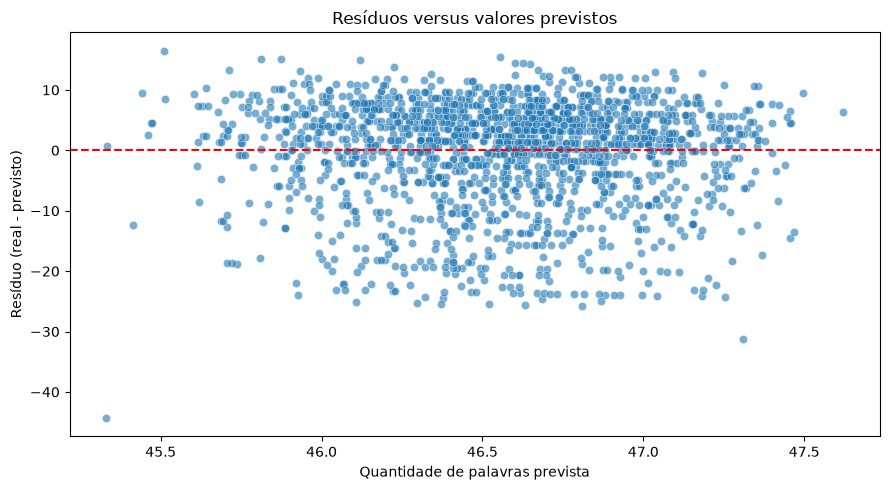

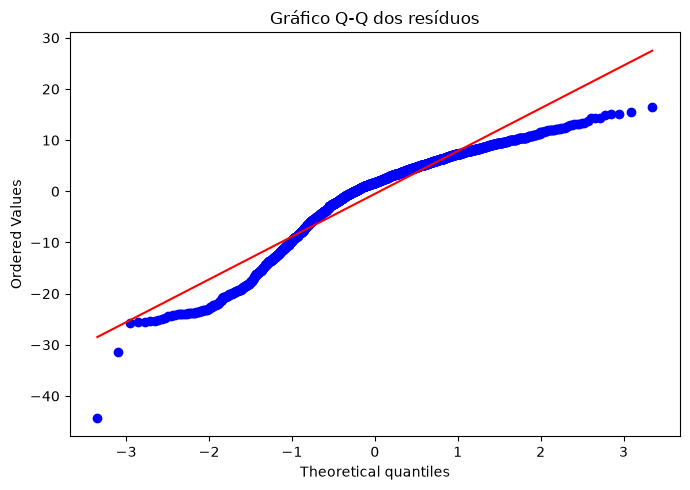

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Valores previstos e resíduos
residuos = y_test.to_numpy() - y_pred

# Gráfico 1: resíduos versus valores previstos
plt.figure(figsize=(9, 5))
sns.scatterplot(x=y_pred, y=residuos, alpha=0.6)
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Quantidade de palavras prevista")
plt.ylabel("Resíduo (real - previsto)")
plt.title("Resíduos versus valores previstos")
plt.tight_layout()
plt.show()

# Gráfico 2: gráfico Q-Q dos resíduos
plt.figure(figsize=(7, 5))
stats.probplot(residuos, dist="norm", plot=plt)
plt.title("Gráfico Q-Q dos resíduos")
plt.tight_layout()
plt.show()

In [8]:
# Modelo de referência: prever sempre a média do conjunto de treino
previsao_media = np.full(len(y_test), y_train.mean())

rmse_media = np.sqrt(
    mean_squared_error(y_test, previsao_media)
)

r2_media = r2_score(y_test, previsao_media)

print(f"R² do modelo linear: {r2:.4f}")
print(f"R² da referência:    {r2_media:.4f}")
print(f"RMSE do modelo:      {rmse:.4f}")
print(f"RMSE da referência:  {rmse_media:.4f}")

R² do modelo linear: -0.0030
R² da referência:    -0.0031
RMSE do modelo:      8.7250
RMSE da referência:  8.7253


## Interpretação dos resultados

O modelo de regressão linear obteve R² de -0,0030 e RMSE de 8,7250 palavras no conjunto de teste. Como referência, foi utilizado um modelo que prevê a média da variável-alvo observada no conjunto de treinamento, que obteve R² de -0,0031 e RMSE de 8,7253.

Os resultados indicam que a regressão linear praticamente não apresentou melhoria em relação ao modelo de referência. O R² negativo indica que o modelo teve desempenho ligeiramente inferior ao de prever a média dos valores reais do conjunto de teste. O RMSE indica um erro quadrático médio em escala equivalente a aproximadamente 8,73 palavras.

### Análise dos gráficos de resíduos

No gráfico de resíduos versus valores previstos, os pontos estão distribuídos ao redor da linha zero, mas existem resíduos extremos e uma dispersão considerável. Isso indica que o modelo não explica bem a variação da quantidade de palavras das descrições.

No gráfico Q-Q, os pontos se afastam da linha de referência, especialmente nas extremidades. Esse comportamento sugere que os resíduos não seguem uma distribuição normal, apresentando desvios e valores extremos.

### Limitações

O baixo desempenho demonstra que as variáveis utilizadas não são suficientes para prever satisfatoriamente a quantidade de palavras da descrição. Além disso, a regressão linear depende de pressupostos que podem não ser atendidos pelos dados analisados.

Portanto, o experimento é útil para compreender o funcionamento da regressão linear e avaliar suas limitações, mas não demonstra capacidade preditiva relevante para essa variável-alvo. Para melhorar o resultado, seria necessário investigar outras variáveis, representações textuais e modelos adequados ao objetivo da análise.